# Controlled modality/branch ablation
M0: profile/behavioral (includes tweet-derived statistics), M1: frozen P1 semantic text, M2: profile/behavioral + seven designated temporal statistics, M3: profile/behavioral + P1, M4: all retained branches.

Capacity changes are explicit; these are not pure causal information ablations. No test access or automatic promotion. Smaller classifiers use true fan-in initialization; shared encoders and final layers are paired. M4 must reproduce historical P1 exactly.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
while not (ROOT / 'src').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.modality_ablation import run, verify
output_dir = run(ROOT)
verification = verify(ROOT, output_dir)
print(verification)

OUTPUT_VERSION: C:\Users\p.vazifeh\Desktop\University\Project\Bot Detection Implementation\results\versions\modality_ablation_v1\20260928T054959860328Z


M4 seed 42: selected epoch 12, BCE 0.567150


M0 seed 42: selected epoch 13, BCE 0.569642


M1 seed 42: selected epoch 46, BCE 0.577280


M2 seed 42: selected epoch 12, BCE 0.567284


...

M0 seed 44: selected epoch 26, BCE 0.560462


M1 seed 44: selected epoch 41, BCE 0.523518


M2 seed 44: selected epoch 23, BCE 0.568305


M3 seed 44: selected epoch 41, BCE 0.544313


{'runs': 15, 'selected_final_checkpoints_reloaded': 30, 'initial_snapshots': 15, 'keyed_predictions_reproduced': 30, 'exact_M4_P1': True, 'paired_encoders_and_final_layer': True, 'excluded_and_missing_input_invariance': True, 'artifact_hashes': 115, 'test_access': False, 'promoted_model': None}


,arm,policy,bot_f1_mean,bot_f1_std,bot_precision_mean,bot_precision_std,bot_recall_mean,bot_recall_std,roc_auc_mean,roc_auc_std,average_precision_mean,average_precision_std,brier_mean,brier_std,validation_unweighted_loss_mean,validation_unweighted_loss_std
0,M0,best_unweighted_validation_loss,0.447731,0.017696,0.348148,0.025660,0.630952,0.041239,0.760365,0.002861,0.546035,0.031749,0.189730,0.008559,0.553903,0.019849
1,M0,last,0.421922,0.014986,0.324275,0.022264,0.607143,0.035714,0.734195,0.013443,0.526840,0.033598,0.207542,0.022538,0.616028,0.060045
2,M1,best_unweighted_validation_loss,0.420982,0.039277,0.353753,0.014016,0.523810,0.089879,0.713978,0.003746,0.348574,0.010091,0.189190,0.015062,0.564898,0.036786
3,M1,last,0.446086,0.013616,0.342790,0.016379,0.642857,0.061859,0.710591,0.003330,0.345143,0.003013,0.206369,0.015681,0.603757,0.038338
4,M2,best_unweighted_validation_loss,0.438498,0.041989,0.348058,0.046741,0.595238,0.020620,0.753797,0.007705,0.530429,0.025744,0.191522,0.007565,0.558389,0.016299
5,M2,last,0.403742,0.043948,0.313528,0.048044,0.571429,0.035714,0.722393,0.002619,0.493755,0.018139,0.212328,0.017622,0.637826,0.043319
6,M3,best_unweighted_validation_loss,0.434377,0.019763,0.357410,0.019130,0.559524,0.074345,0.745587,0.008360,0.545469,0.023750,0.183537,0.012811,0.551339,0.018629
7,M3,last,0.413482,0.011902,0.335352,0.032533,0.547619,0.054554,0.727114,0.002910,0.503646,0.059794,0.196220,0.023491,0.617942,0.065114
8,M4,best_unweighted_validation_loss,0.494172,0.028423,0.402980,0.038937,0.642857,0.035714,0.756671,0.006620,0.548662,0.016240,0.177880,0.015646,0.541210,0.022535
9,M4,last,0.460989,0.081045,0.375882,0.092667,0.607143,0.035714,0.737890,0.027935,0.520536,0.022614,0.192516,0.037245,0.606176,0.095931


,comparison,seed,policy,parameter_delta,delta_bot_f1,delta_bot_precision,delta_bot_recall,delta_roc_auc,delta_average_precision,delta_brier,delta_validation_unweighted_loss
0,M2-M0,42,best_unweighted_validation_loss,752,-0.005500,0.013605,-0.071429,-0.010776,-0.008021,-0.002052,-0.002359
1,M2-M0,43,best_unweighted_validation_loss,752,0.013120,0.017571,0.000000,0.000000,-0.026350,0.002664,0.007974
2,M2-M0,44,best_unweighted_validation_loss,752,-0.035318,-0.031447,-0.035714,-0.008929,-0.012446,0.004762,0.007843
3,M2-M0,42,last,752,0.004877,0.005519,0.000000,0.005234,-0.010298,-0.006420,0.000515
4,M2-M0,43,last,752,0.012012,0.015810,0.000000,-0.015086,-0.040327,0.007620,0.036103
5,M2-M0,44,last,752,-0.071429,-0.053571,-0.107143,-0.025554,-0.048632,0.013159,0.028776
6,M3-M0,42,best_unweighted_validation_loss,12816,0.008637,0.019608,-0.035714,-0.003695,0.015005,0.000458,0.002816
7,M3-M0,43,best_unweighted_validation_loss,12816,-0.049087,-0.036869,-0.071429,-0.015086,0.005426,0.001251,0.005641
8,M3-M0,44,best_unweighted_validation_loss,12816,0.000389,0.045045,-0.107143,-0.025554,-0.022127,-0.020290,-0.016149
9,M3-M0,42,last,12816,-0.004762,-0.005326,0.000000,0.003695,-0.061798,-0.006682,0.018643


[
  {
    "comparison": "M2-M0",
    "all_three_f1_improve": false,
    "mean_delta_f1": -0.009232861877422041,
    "mean_delta_ap": -0.015605518739526055,
    "metrics_pass": false,
    "requires_verification": true,
    "automatic_promotion": false
  },
  {
    "comparison": "M3-M0",
    "all_three_f1_improve": false,
    "mean_delta_f1": -0.013353298351615342,
    "mean_delta_ap": -0.0005654486618860884,
    "metrics_pass": false,
    "requires_verification": true,
    "automatic_promotion": false
  },
  {
    "comparison": "M4-M2",
    "all_three_f1_improve": true,
    "mean_delta_f1": 0.055673750743005436,
    "mean_delta_ap": 0.01823266526357792,
    "metrics_pass": true,
    "requires_verification": true,
    "automatic_promotion": false
  },
  {
    "comparison": "M4-M3",
    "all_three_f1_improve": true,
    "mean_delta_f1": 0.05979418721719874,
    "mean_delta_ap": 0.003192595185937952,
    "metrics_pass": true,
    "requires_verification": true,
    "automatic_promotion": fa

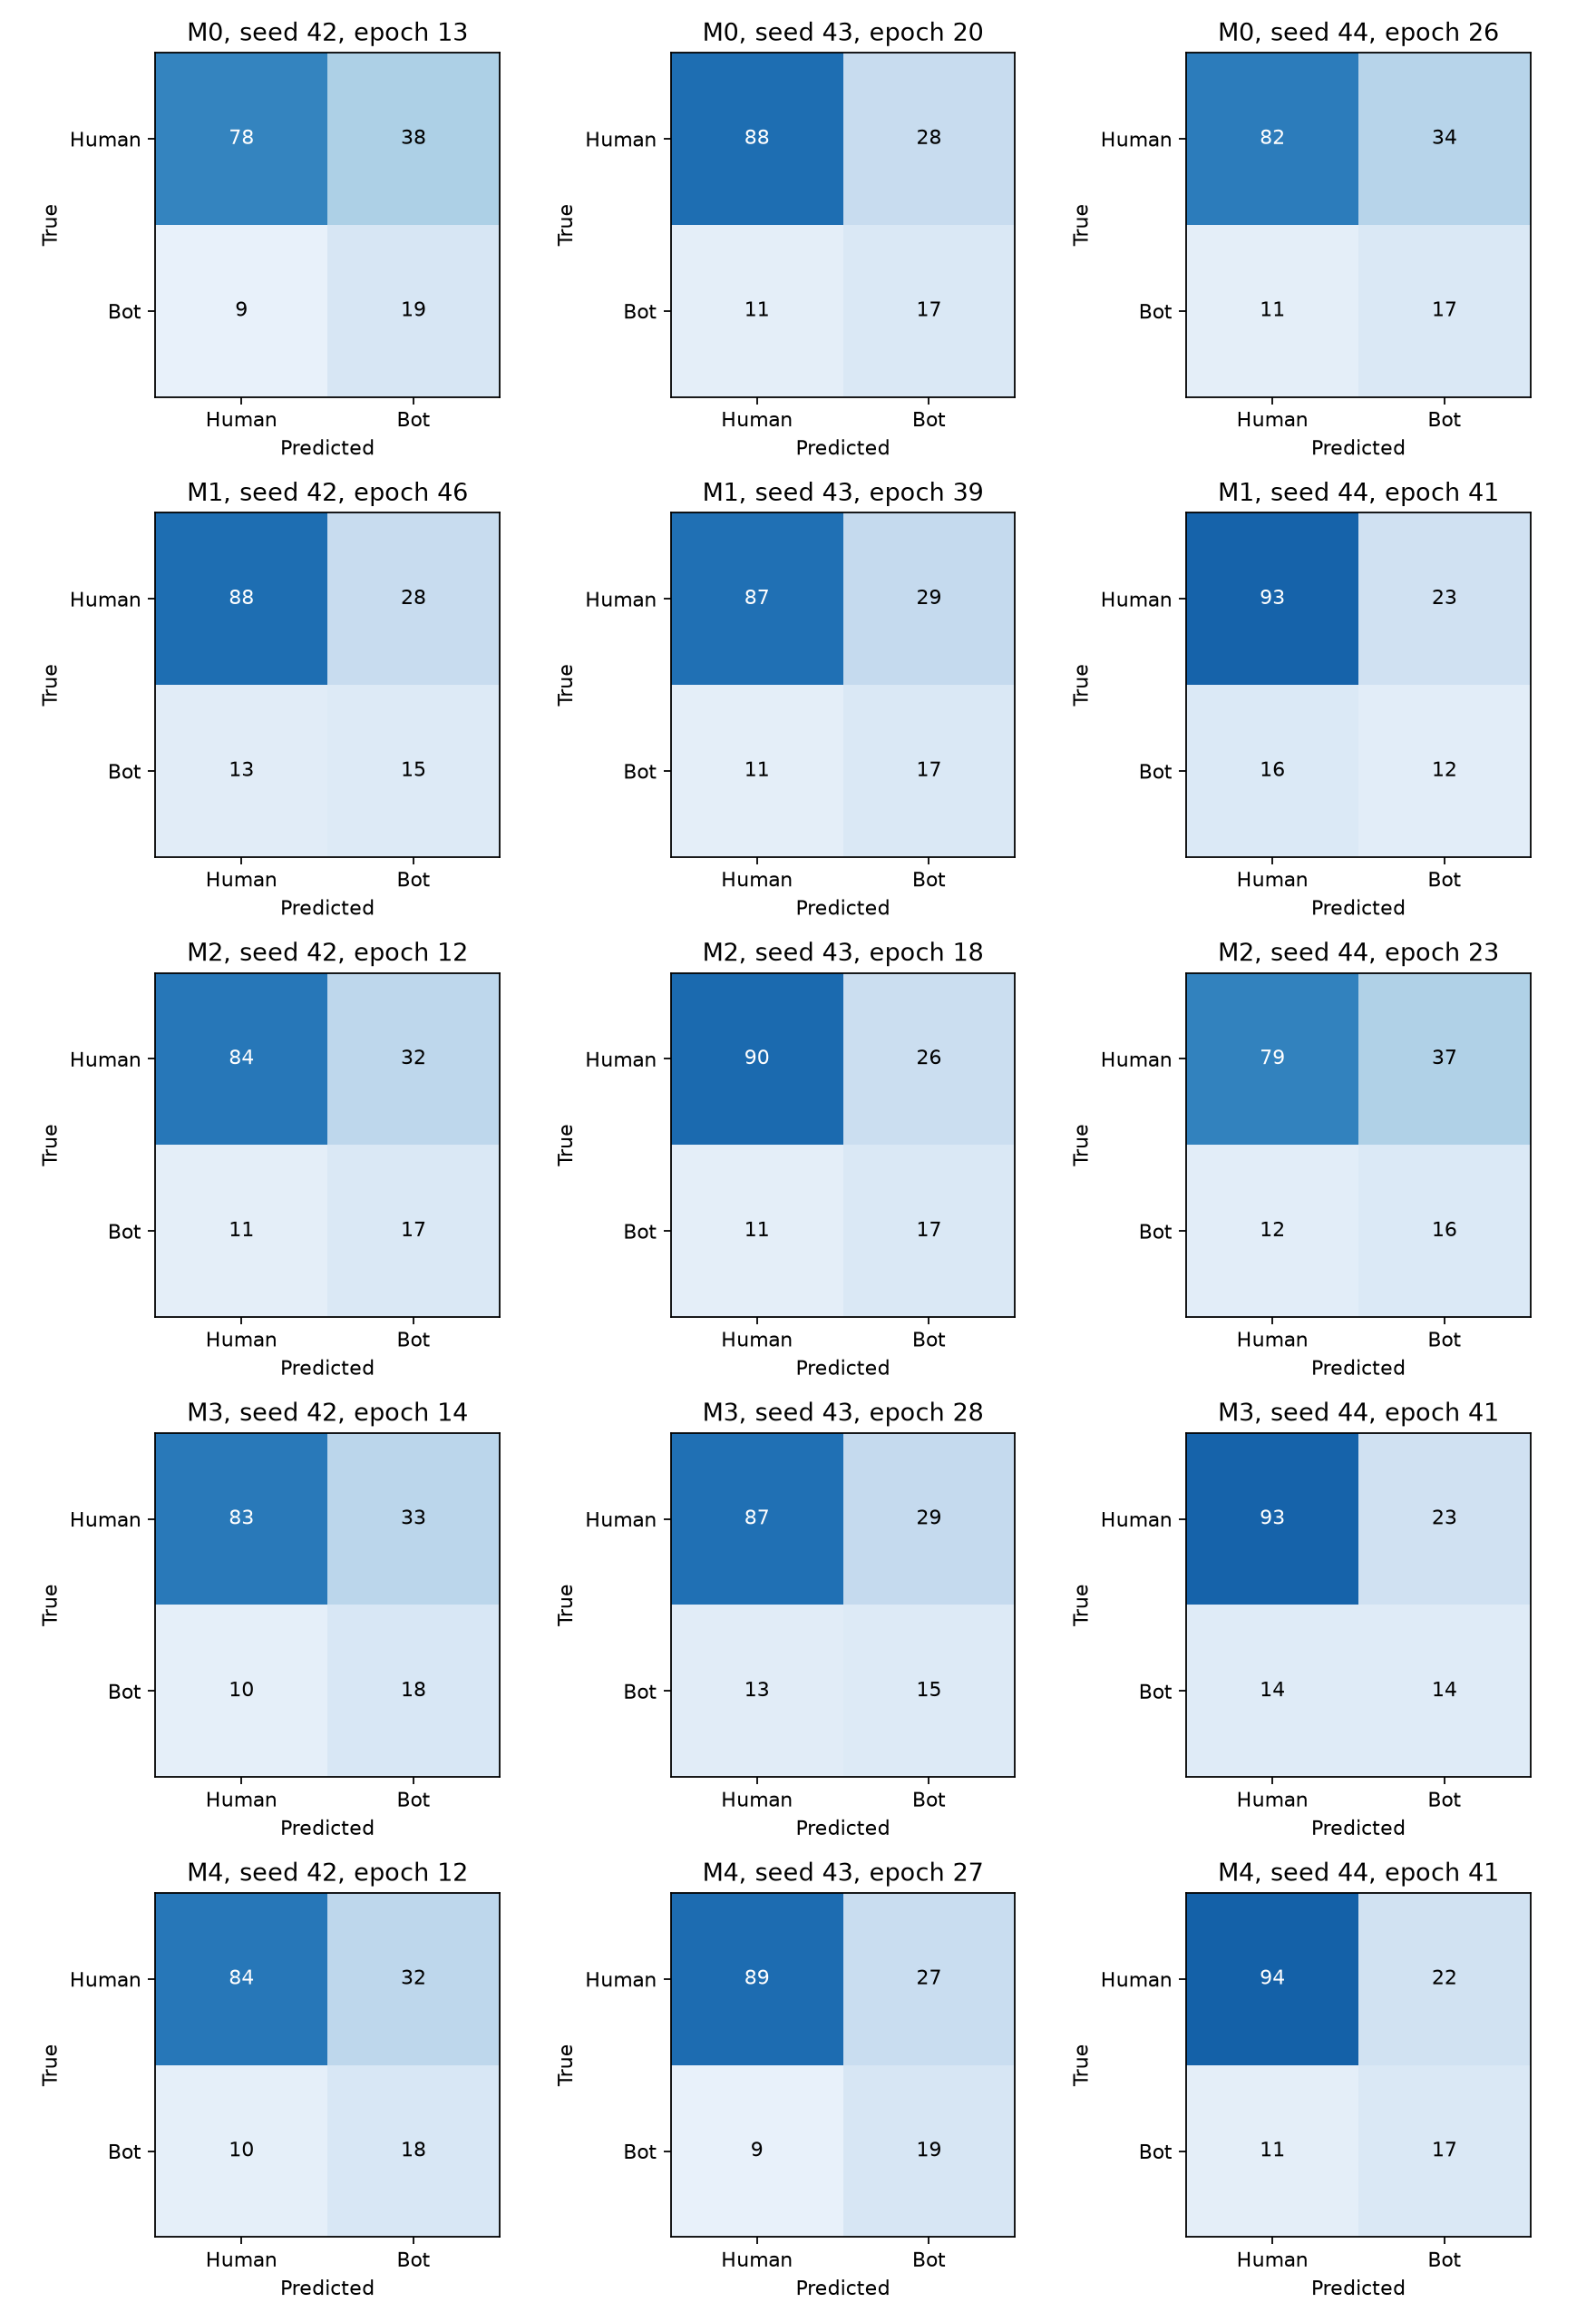

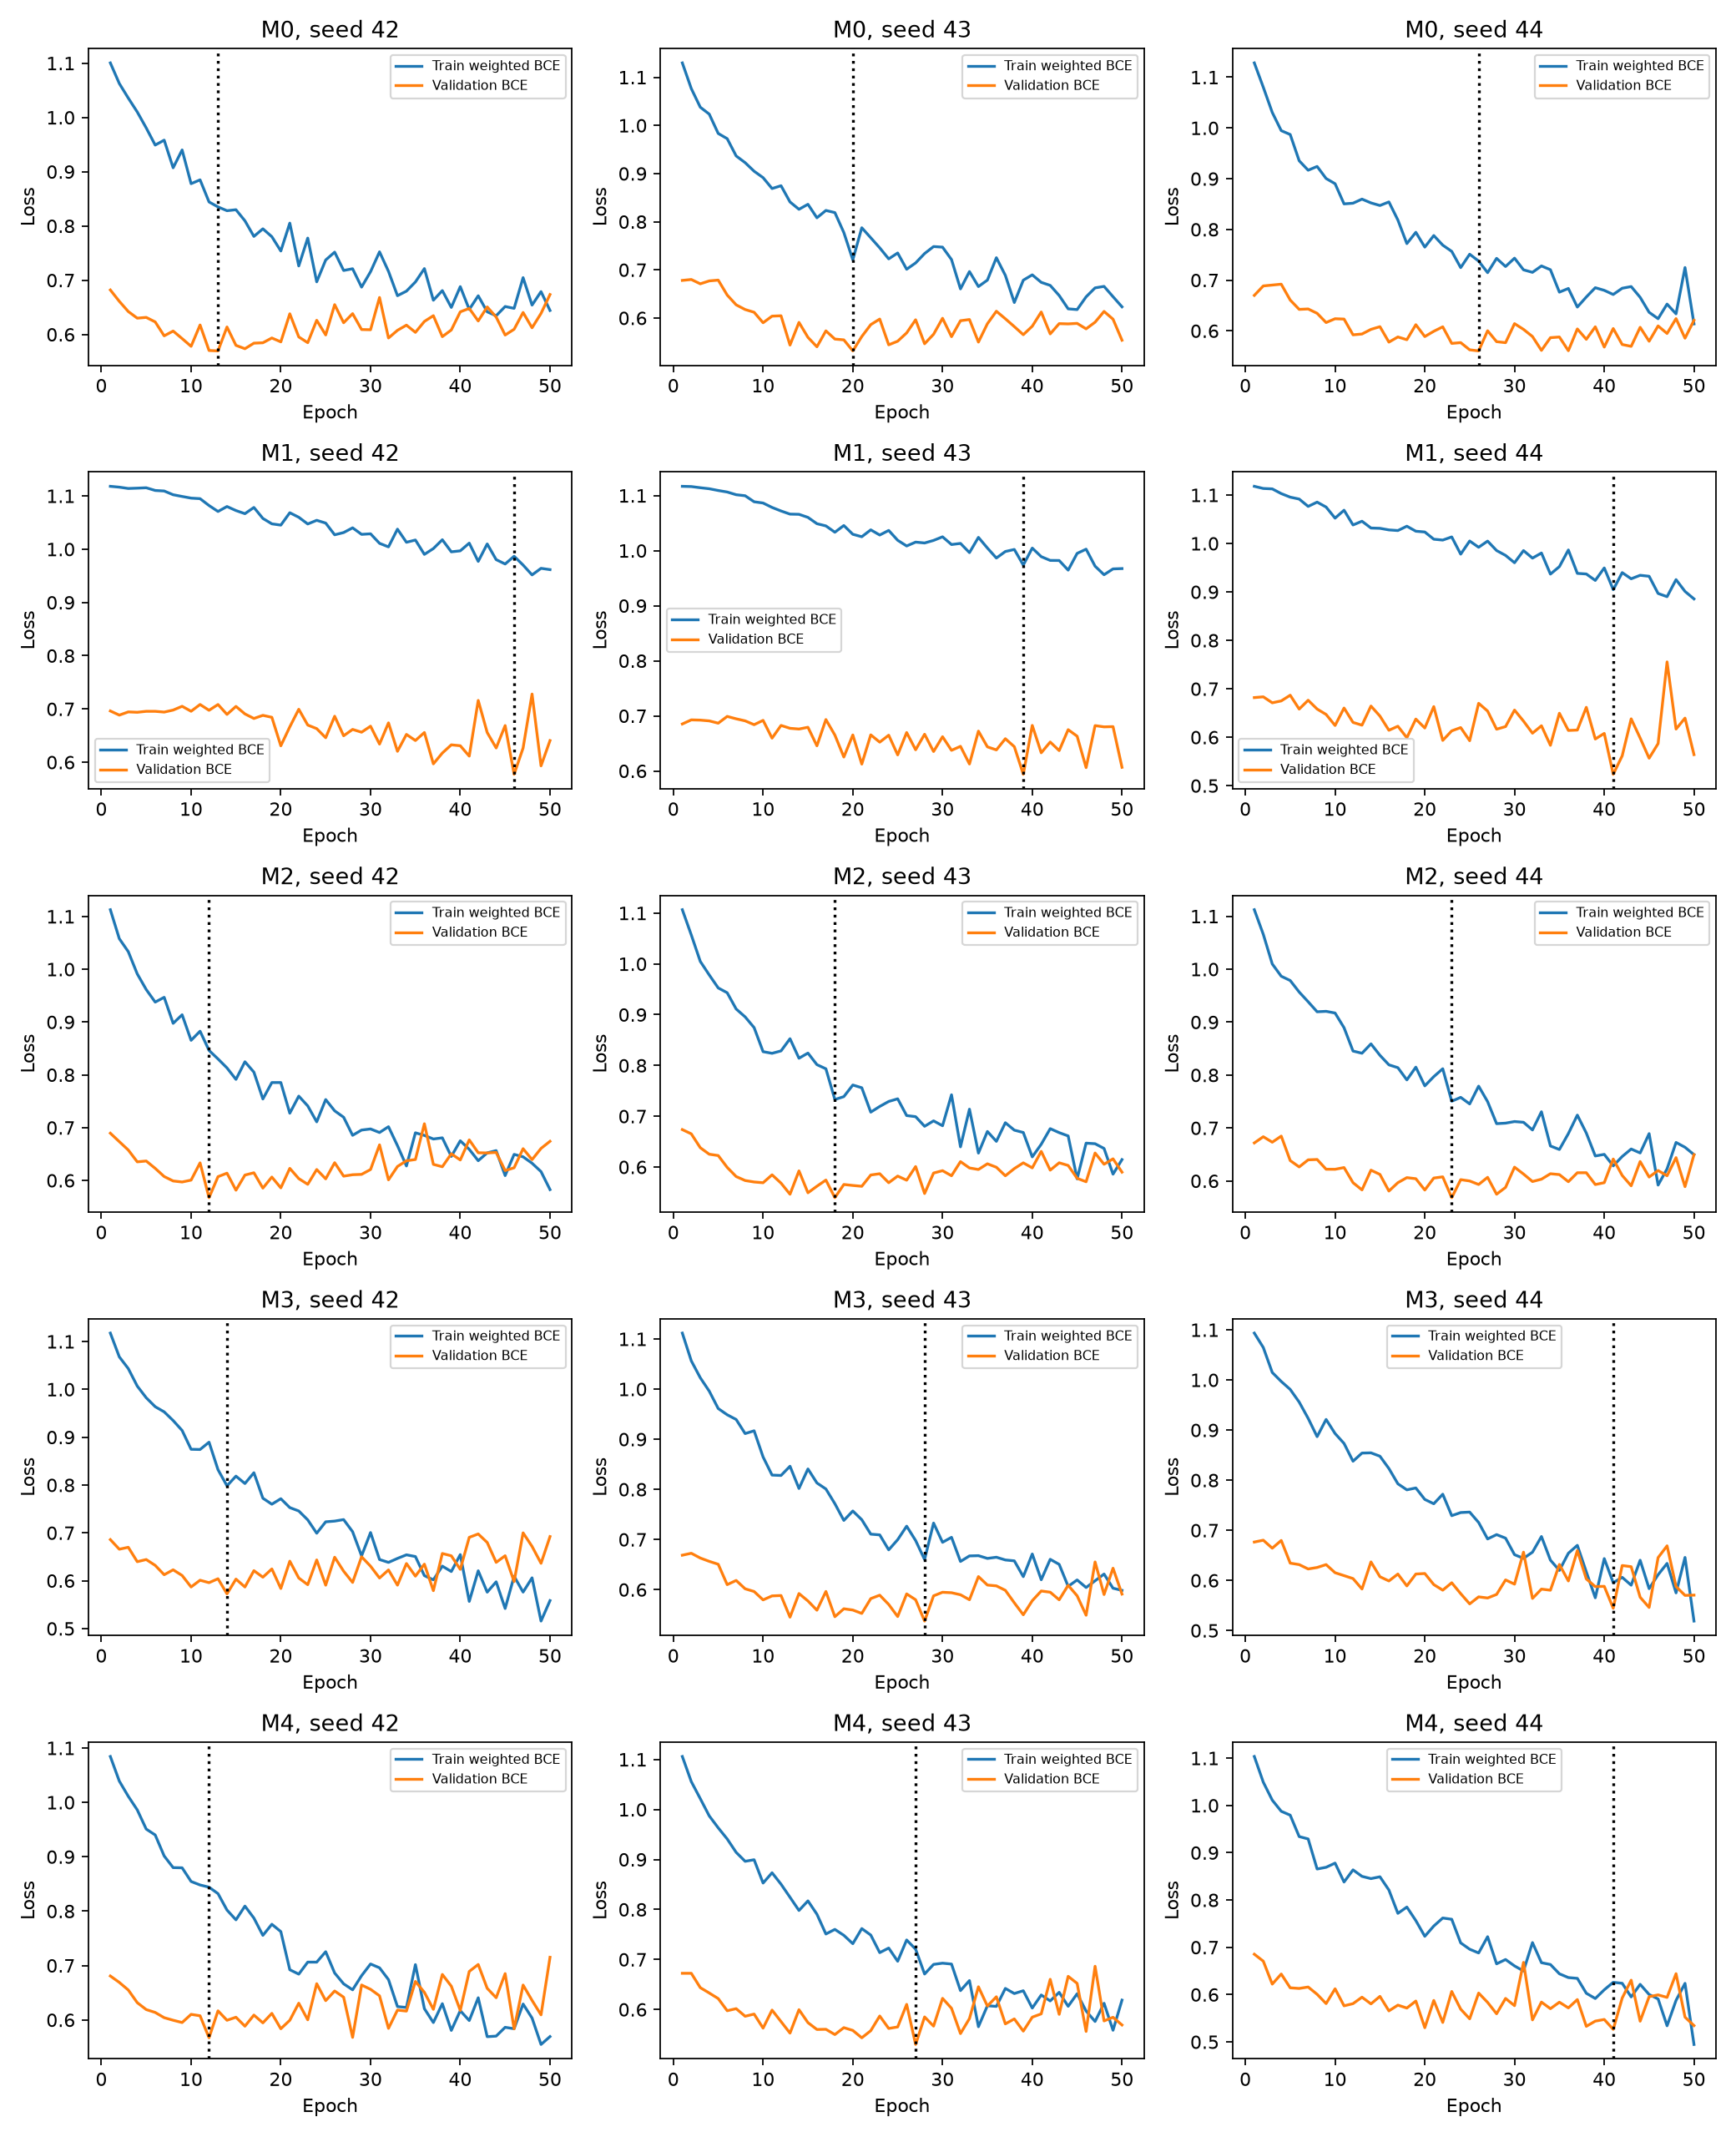

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv(output_dir / 'seed_summary.csv'))
display(pd.read_csv(output_dir / 'paired_effects.csv'))
print((output_dir / 'development_decisions.json').read_text())
display(Image(filename=str(output_dir / 'figures/confusion_selected.png')))
display(Image(filename=str(output_dir / 'figures/learning_curves.png')))